# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Farhan Putra Pratama
- **Email:** 
- **ID Dicoding:** 

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menyumbang revenue dan jumlah order tertinggi serta terendah sepanjang 2017, dan bagaimana tren revenue bulanannya dari Januari 2017 sampai Agustus 2018?
- **Pertanyaan 2:** Di state mana persentase pesanan yang terlambat dikirim (delivered lebih lambat dari estimasi) paling tinggi pada 2017–2018, dan bagaimana kaitannya dengan rata-rata skor review?

## Import Semua Packages/Library yang Digunakan

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Data Wrangling

## Gathering Data

 Memuat semua dataset

In [36]:
path = "/content/data/"

customers = pd.read_csv(path+"customers_dataset.csv")
orders    = pd.read_csv(path+"orders_dataset.csv")
items     = pd.read_csv(path+"order_items_dataset.csv")
products  = pd.read_csv(path+"products_dataset.csv")
translate = pd.read_csv(path+"product_category_name_translation.csv")
reviews   = pd.read_csv(path+"order_reviews_dataset.csv")
payments  = pd.read_csv(path+"order_payments_dataset.csv")

In [37]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [38]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [39]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [40]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [41]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


**Insight:** (Opsional)
- Dataset terdiri dari beberapa tabel terpisah (customers, orders, order_items, products, order_reviews, dan tabel terjemahan kategori) yang berhasil dimuat ke DataFrame tanpa error, sehingga siap dinilai kualitasnya pada tahap Assessing.
- Tabel orders menjadi tabel pusat karena memuat status pesanan dan seluruh tanggal proses (pembelian, pengiriman, estimasi tiba). Tabel ini dihubungkan ke customers lewat customer_id, ke order_items dan order_reviews lewat order_id, dan ke products lewat product_id.
- Kolom tanggal pada orders masih tampil sebagai teks, dan nama kategori produk pada products masih berbahasa Portugis. Keduanya perlu ditangani pada tahap Cleaning, yaitu mengubah tipe data tanggal dan menerjemahkan kategori memakai tabel translasi.
- Tabel customers memiliki dua jenis ID, yaitu customer_id dan customer_unique_id. Satu pelanggan bisa punya beberapa customer_id, jadi customer_unique_id dipakai untuk analisis perilaku pelanggan seperti RFM.

### Assessing Data

### Pemeriksaan menyeluruh semua tabel (tipe data, missing value, duplikat)

In [42]:
tables = {"customers": customers, "orders": orders, "items": items,
          "products": products, "reviews": reviews, "translate": translate}

for name, df in tables.items():
    print(f"===== {name} =====")
    df.info()
    missing = df.isna().sum()
    print("Missing value:")
    print(missing[missing > 0] if missing.sum() > 0 else "tidak ada")
    print("Duplikat:", df.duplicated().sum())
    print()

===== customers =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
Missing value:
tidak ada
Duplikat: 0

===== orders =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441

### Pemeriksaan khusus per tabel

In [43]:
# customers: satu orang bisa punya banyak customer_id
print("customer_id unik       :", customers["customer_id"].nunique())
print("customer_unique_id unik:", customers["customer_unique_id"].nunique())

# items: nilai tidak valid dan outlier harga
print("\nHarga <= 0:", (items["price"] <= 0).sum())
q1, q3 = items["price"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
print("Batas atas outlier harga:", round(batas_atas, 2))
print("Jumlah outlier harga    :", (items["price"] > batas_atas).sum())
print("Harga maksimum          :", items["price"].max())

# products: kategori kosong dan kategori tanpa terjemahan
print("\nProduk tanpa kategori:", products["product_category_name"].isna().sum())
kat_produk = set(products["product_category_name"].dropna().unique())
kat_translate = set(translate["product_category_name"].unique())
print("Kategori tanpa terjemahan:", kat_produk - kat_translate)

customer_id unik       : 99441
customer_unique_id unik: 96096

Harga <= 0: 0
Batas atas outlier harga: 277.4
Jumlah outlier harga    : 8427
Harga maksimum          : 6735.0

Produk tanpa kategori: 610
Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


### Masalah 1: Tipe data tanggal salah (Invalid value) pada order.csv




In [44]:
orders.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object


### Masalah 2: Missing value pada order.csv, kolom tanggal pengiriman kosong

In [45]:
print(orders.isna().sum())
print()
print(orders["order_status"].value_counts())
print()
print("Status pesanan yang tanggal diterima pelanggannya kosong:")
print(orders[orders["order_delivered_customer_date"].isna()]["order_status"].value_counts())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Status pesanan yang tanggal diterima pelanggannya kosong:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


### Masalah 3: Satu pesanan bisa punya lebih dari satu review (Duplicate data pada level pesanan). Jika langsung digabung, baris pesanan akan terduplikasi.

In [46]:
tables = {"customers": customers, "orders": orders, "items": items,
          "products": products, "reviews": reviews, "translate": translate}

print("Jumlah order_id yang muncul lebih dari sekali di reviews:", reviews["order_id"].duplicated().sum())
print("Jumlah baris duplikat penuh di semua tabel:")
print({k: int(v.duplicated().sum()) for k, v in tables.items()})

Jumlah order_id yang muncul lebih dari sekali di reviews: 551
Jumlah baris duplikat penuh di semua tabel:
{'customers': 0, 'orders': 0, 'items': 0, 'products': 0, 'reviews': 0, 'translate': 0}


**Steps to Take:**
- Masalah 1:
1. Ubah kelima kolom tanggal di orders ke datetime.
2. Cek ulang dengan .dtypes.
- Masalah 2:
1. Pertahankan hanya pesanan berstatus delivered.
2. Buang pesanan delivered yang tanggal diterima pelanggannya kosong.
3. Kolom order_approved_at (160 kosong) dibiarkan, karena tidak dipakai di analisis.
4. Cek ulang jumlah missing pada kolom yang dipakai.
- Masalah 3:
1. Ambil rata-rata review_score per order_id, sehingga satu pesanan hanya punya satu baris.
2. Cek ulang bahwa order_id tidak lagi duplikat.
3. Baru gabungkan ke tabel utama.

**Insight:** (Opsional)
- Masalah 1: Kelima kolom tanggal pada tabel orders terbaca sebagai object (teks), sehingga tidak bisa dipakai untuk menghitung selisih hari atau mengelompokkan data per bulan. Kolom ini perlu diubah ke datetime karena dibutuhkan untuk menentukan keterlambatan pengiriman (is_late), lama pengiriman (delivery_days), dan tren revenue bulanan.
- Masalah 2:Kolom order_delivered_customer_date kosong pada 2.965 pesanan (sekitar 3% dari 99.441 pesanan). Hampir semuanya (2.957 pesanan) berstatus belum selesai seperti shipped, canceled, unavailable, invoiced, processing, created, dan approved, jadi kosongnya data wajar karena barang belum sampai ke pelanggan, bukan karena kesalahan input. Hanya 8 pesanan berstatus delivered yang tanggal diterimanya kosong, dan ini janggal sehingga dibuang. Analisis difokuskan pada pesanan delivered (sekitar 97% data) agar perhitungan revenue dan keterlambatan hanya memakai transaksi yang benar-benar selesai. Kolom order_approved_at (160 kosong) dan order_delivered_carrier_date (1.783 kosong) tidak dipakai dalam analisis, sehingga tidak ditangani.
- Masalah 3: Ditemukan 551 order_id yang muncul lebih dari sekali di tabel reviews, padahal jumlah baris duplikat penuh di semua tabel adalah 0. Artinya ini bukan duplikat murni, melainkan satu pesanan yang punya lebih dari satu review (dengan review_id berbeda), sehingga drop_duplicates() tidak menyelesaikan masalah ini. Jika langsung digabung, baris pesanan akan berlipat dan revenue serta jumlah pesanan terhitung ganda. Solusinya mengagregasi skor review menjadi rata-rata per order_id sebelum penggabungan, agar satu pesanan tetap mewakili satu skor review.

### Cleaning Data

### 1. Ubah tipe data pada tabel order menjadi datetime

In [47]:
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

orders[date_cols].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [48]:
# items: ubah tipe data tanggal
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

# reviews: ubah tipe data tanggal, lalu buang kolom komentar (tidak dipakai analisis)
for c in ["review_creation_date", "review_answer_timestamp"]:
    reviews[c] = pd.to_datetime(reviews[c])
reviews = reviews.drop(columns=["review_comment_title", "review_comment_message"])

# items: outlier harga DIPERTAHANKAN
# (produk bernilai tinggi yang wajar, bukan kesalahan input)

items[["shipping_limit_date"]].dtypes

,0
shipping_limit_date,datetime64[ns]


Outlier harga dipertahankan karena merupakan produk mahal yang valid, bukan data salah. Menghapusnya akan menghilangkan transaksi nyata dan mengubah total revenue.
Kolom komentar review dibuang karena banyak yang kosong dan tidak dipakai di analisis, sementara review_score yang dipakai sudah lengkap.
Kategori kosong dan tanpa terjemahan sudah ditangani di langkah cleaning kategori yang Anda punya.

### 2. Hapus duplikasi data pada beberapa table

In [49]:
for df in [customers, orders, items, products, reviews]:
    df.drop_duplicates(inplace=True)

print({k: int(v.duplicated().sum()) for k, v in tables.items()})

{'customers': 0, 'orders': 0, 'items': 0, 'products': 0, 'reviews': 0, 'translate': 0}


### 3. Penanganan Missing value pada tanggla pengiriman

In [50]:
orders_delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"])

print("Jumlah pesanan delivered yang dipakai:", orders_delivered.shape[0])
orders_delivered[["order_purchase_timestamp", "order_delivered_customer_date",
                  "order_estimated_delivery_date"]].isna().sum()

Jumlah pesanan delivered yang dipakai: 96470


,0
order_purchase_timestamp,0
order_delivered_customer_date,0
order_estimated_delivery_date,0


### 4. Penanganan kategori produk kosong dan terjemahkan ke Inggris

In [51]:
products = products.merge(translate, on="product_category_name", how="left")

# kategori tanpa terjemahan -> pakai nama asli; yang benar-benar kosong -> "unknown"
products["product_category_name_english"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"])
    .fillna("unknown"))

products["product_category_name_english"].isna().sum()

np.int64(0)

### 5. Menyamakan review ke level pesanan (rata-rata skor per order_id)



In [52]:
review_order = reviews.groupby("order_id", as_index=False)["review_score"].mean()
review_order["order_id"].duplicated().sum()

np.int64(0)

### 6. Menggabungkan semua tabel menjadi satu file csv(main_data.csv)

In [53]:
main = (orders_delivered
        .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
               on="customer_id", how="left")
        .merge(items[["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value"]],
               on="order_id", how="inner")
        .merge(products[["product_id", "product_category_name_english"]],
               on="product_id", how="left")
        .merge(review_order, on="order_id", how="left"))

main["product_category_name_english"] = main["product_category_name_english"].fillna("unknown")

# kolom turunan
main["revenue"] = main["price"]
main["is_late"] = main["order_delivered_customer_date"] > main["order_estimated_delivery_date"]
main["delivery_days"] = (main["order_delivered_customer_date"] - main["order_purchase_timestamp"]).dt.days
main["purchase_year"] = main["order_purchase_timestamp"].dt.year
main["purchase_month"] = main["order_purchase_timestamp"].dt.to_period("M").astype(str)

print(main.shape)
main.head()

(110189, 23)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,order_item_id,product_id,seller_id,price,freight_value,product_category_name_english,review_score,revenue,is_late,delivery_days,purchase_year,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,housewares,4.0,29.99,False,8,2017,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,perfumery,4.0,118.70,False,13,2018,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,auto,5.0,159.90,False,9,2018,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,45.00,27.20,pet_shop,5.0,45.00,False,13,2017,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,stationery,5.0,19.90,False,2,2018,2018-02


**Insight:** (Opsional)

Proses cleaning membuat data lebih konsisten dan siap dianalisis. Kolom tanggal diubah ke tipe datetime agar bisa dipakai untuk menghitung lama pengiriman, keterlambatan, dan tren bulanan. Pemeriksaan duplikasi tidak menemukan baris ganda penuh, sehingga tidak ada data yang terbuang. Pesanan dengan tanggal pengiriman kosong dikeluarkan karena sebagian besar belum selesai atau dibatalkan, sehingga analisis hanya memakai transaksi yang benar-benar sampai ke pelanggan. Kategori produk yang kosong diberi label unknown dan nama kategori diterjemahkan ke bahasa Inggris agar mudah dibaca. Skor review dirata-rata per pesanan supaya satu pesanan hanya punya satu skor dan tidak terhitung ganda saat digabung. Terakhir, seluruh tabel digabung menjadi satu dataset utama (main_data.csv) yang menjadi dasar EDA, visualisasi, dan dashboard.

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan 1: Kategori produk apa saja yang menyumbang revenue dan jumlah order tertinggi serta terendah sepanjang 2017, dan bagaimana tren revenue bulanannya dari Januari 2017 sampai Agustus 2018?

In [54]:
main_2017 = main[main["purchase_year"] == 2017]

category_2017 = (main_2017.groupby("product_category_name_english")
                 .agg(total_revenue=("revenue", "sum"),
                      total_orders=("order_id", "nunique"))
                 .sort_values("total_revenue", ascending=False))

print("5 kategori revenue tertinggi 2017")
display(category_2017.head(5))
print("5 kategori revenue terendah 2017")
display(category_2017.tail(5))

5 kategori revenue tertinggi 2017


,total_revenue,total_orders
product_category_name_english,,
bed_bath_table,490596.92,4423
watches_gifts,475610.71,2073
health_beauty,473833.00,3305
sports_leisure,435495.14,3539
computers_accessories,391786.29,2546


5 kategori revenue terendah 2017


,total_revenue,total_orders
product_category_name_english,,
fashion_childrens_clothes,349.98,4
security_and_services,283.29,2
flowers,270.50,8
arts_and_craftmanship,151.89,2
diapers_and_hygiene,76.00,1


In [55]:
periode = main[(main["order_purchase_timestamp"] >= "2017-01-01") &
               (main["order_purchase_timestamp"] < "2018-09-01")]

monthly = (periode.groupby("purchase_month")
           .agg(total_revenue=("revenue", "sum"),
                total_orders=("order_id", "nunique"))
           .reset_index())
monthly["mom_growth_pct"] = monthly["total_revenue"].pct_change() * 100
monthly

,purchase_month,total_revenue,total_orders,mom_growth_pct
0,2017-01,111798.36,750,NaN
1,2017-02,234223.40,1653,109.505220
2,2017-03,359198.85,2546,53.357372
3,2017-04,340669.68,2303,-5.158471
4,2017-05,489159.25,3545,43.587551
5,2017-06,421923.37,3135,-13.745192
6,2017-07,481604.52,3872,14.145021
7,2017-08,554699.70,4193,15.177428
8,2017-09,607399.67,4150,9.500631
9,2017-10,648247.65,4478,6.725058


In [56]:
print("Bulan revenue tertinggi:", monthly.loc[monthly["total_revenue"].idxmax(), "purchase_month"])
print("Rata-rata pertumbuhan MoM (%):", round(monthly["mom_growth_pct"].mean(), 2))
monthly["total_revenue"].describe()

Bulan revenue tertinggi: 2017-11
Rata-rata pertumbuhan MoM (%): 14.69


,total_revenue
count,20.000000
mean,658988.897500
std,272780.333445
min,111798.360000
25%,466684.232500
50%,687140.420000
75%,881776.102500
max,987648.070000


### Explore Pertanyaan 2: Di state mana persentase pesanan yang terlambat dikirim (delivered lebih lambat dari estimasi) paling tinggi pada 2017–2018, dan bagaimana kaitannya dengan rata-rata skor review?

In [57]:
# analisis level pesanan: satu baris = satu pesanan
order_level = main.drop_duplicates("order_id")
order_level = order_level[order_level["purchase_year"].isin([2017, 2018])]

print("Persentase keterlambatan nasional (%):", round(order_level["is_late"].mean() * 100, 2))

state_stats = (order_level.groupby("customer_state")
               .agg(total_orders=("order_id", "nunique"),
                    late_pct=("is_late", lambda x: x.mean() * 100),
                    avg_review=("review_score", "mean"),
                    avg_delivery_days=("delivery_days", "mean"))
               .reset_index())

# state dengan pesanan terlalu sedikit dikeluarkan agar persentase tidak menyesatkan
state_stats = state_stats[state_stats["total_orders"] >= 100].sort_values("late_pct", ascending=False)
state_stats

Persentase keterlambatan nasional (%): 8.13


,customer_state,total_orders,late_pct,avg_review,avg_delivery_days
1,AL,396,23.989899,3.852417,24.017677
9,MA,713,19.635344,3.830042,21.078541
16,PI,475,16.000000,3.993617,18.976842
5,CE,1273,15.396701,3.937648,20.789474
24,SE,332,15.361446,3.900302,20.948795
4,BA,3253,14.048571,3.929634,18.865048
18,RJ,12310,13.517465,3.965193,14.836149
26,TO,274,12.773723,4.153846,17.226277
13,PA,942,12.420382,3.908504,23.299363
7,ES,1992,12.248996,4.079858,15.317771


In [58]:
print("Rata-rata review: pesanan terlambat vs tepat waktu")
review_late = order_level.groupby("is_late")["review_score"].mean()
display(review_late)

print("Korelasi antar state: % terlambat vs rata-rata review")
state_stats[["late_pct", "avg_review"]].corr()

Rata-rata review: pesanan terlambat vs tepat waktu


,review_score
is_late,
False,4.295086
True,2.566728


Korelasi antar state: % terlambat vs rata-rata review


,late_pct,avg_review
late_pct,1.000000,-0.874983
avg_review,-0.874983,1.000000


**Insight:** (Opsional)
- Pertanyaan 1, Revenue per kategori (2017) dan tren bulanan:
  1. Kategori revenue tertinggi 2017 didominasi kategori rumah tangga, kesehatan, dan olahraga.
  2. Kategori revenue terendah hampir tidak berkontribusi. Kelima kategori terbawah (fashion_childrens_clothes, security_and_services, flowers, arts_and_craftmanship, diapers_and_hygiene) masing-masing hanya menghasilkan di bawah R$350 dengan 1 sampai 8 pesanan sepanjang 2017.
  3. Revenue bulanan tumbuh pesat sepanjang 2017, mencapai puncak di November 2017, lalu cenderung stabil di 2018.
- Pertanyaan 2, Keterlambatan pengiriman per state:
  1. Keterlambatan terkonsentrasi di wilayah Timur Laut dan Rio de Janeiro.
  2. Keterlambatan sangat menurunkan kepuasan pelanggan.
  3. Lama pengiriman bukan satu-satunya penentu keterlambatan. Persoalan ada pada akurasi estimasi pengiriman, selain kecepatan logistik. Perbaikan bisa dilakukan lewat evaluasi mitra logistik dan penyesuaian estimasi tiba di state yang keterlambatannya tinggi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah (2017)

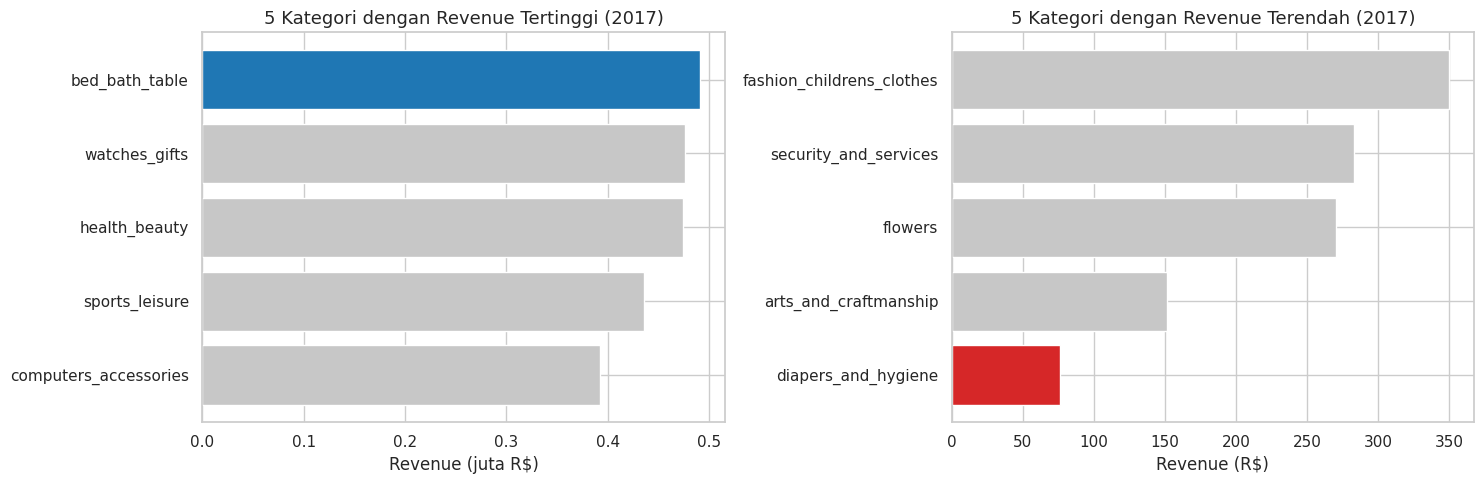

In [59]:
top5 = category_2017.head(5)
bottom5 = category_2017.tail(5)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

colors_top = ["#1f77b4"] + ["#c7c7c7"] * 4
ax[0].barh(top5.index[::-1], (top5["total_revenue"] / 1e6)[::-1], color=colors_top[::-1])
ax[0].set_title("5 Kategori dengan Revenue Tertinggi (2017)", fontsize=13)
ax[0].set_xlabel("Revenue (juta R$)")

colors_bottom = ["#d62728"] + ["#c7c7c7"] * 4
ax[1].barh(bottom5.index[::-1], bottom5["total_revenue"][::-1], color=colors_bottom)
ax[1].set_title("5 Kategori dengan Revenue Terendah (2017)", fontsize=13)
ax[1].set_xlabel("Revenue (R$)")

plt.tight_layout()
plt.show()

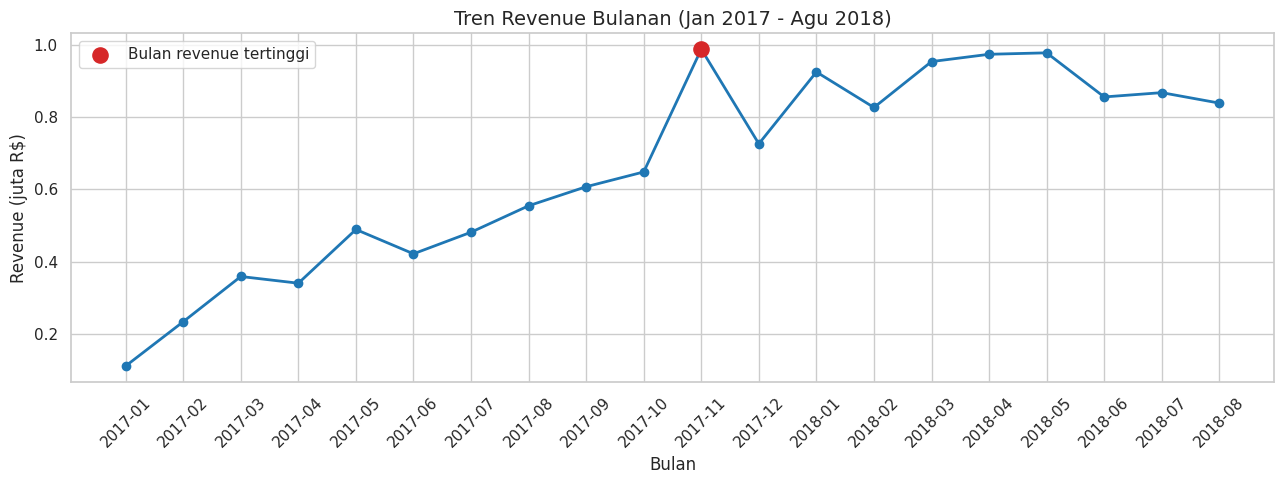

In [60]:
plt.figure(figsize=(13, 5))
plt.plot(monthly["purchase_month"], monthly["total_revenue"] / 1e6,
         marker="o", color="#1f77b4", linewidth=2)
idx_max = monthly["total_revenue"].idxmax()
plt.scatter(monthly.loc[idx_max, "purchase_month"],
            monthly.loc[idx_max, "total_revenue"] / 1e6, color="#d62728", s=120, zorder=5,
            label="Bulan revenue tertinggi")
plt.title("Tren Revenue Bulanan (Jan 2017 - Agu 2018)", fontsize=14)
plt.xlabel("Bulan")
plt.ylabel("Revenue (juta R$)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Keterlambatan pengiriman per state dan hubungannya dengan review

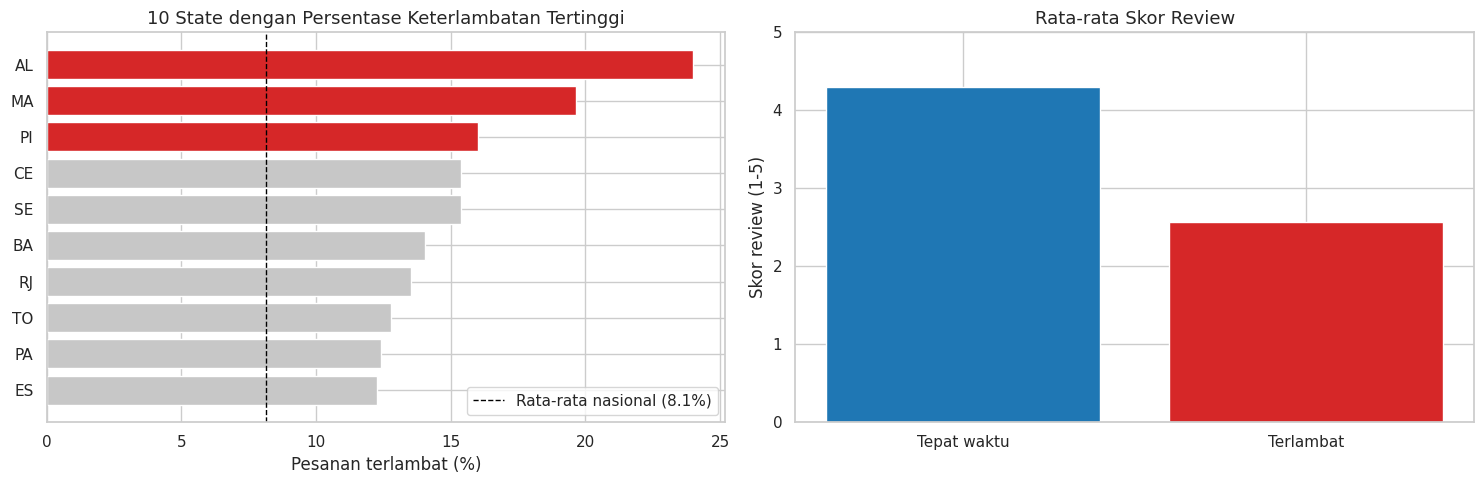

In [61]:
top10_late = state_stats.head(10)
nasional = order_level["is_late"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

colors = ["#d62728"] * 3 + ["#c7c7c7"] * 7
ax[0].barh(top10_late["customer_state"][::-1], top10_late["late_pct"][::-1], color=colors[::-1])
ax[0].axvline(nasional, color="black", linestyle="--", linewidth=1, label=f"Rata-rata nasional ({nasional:.1f}%)")
ax[0].set_title("10 State dengan Persentase Keterlambatan Tertinggi", fontsize=13)
ax[0].set_xlabel("Pesanan terlambat (%)")
ax[0].legend()

ax[1].bar(["Tepat waktu", "Terlambat"],
          [review_late.get(False, np.nan), review_late.get(True, np.nan)],
          color=["#1f77b4", "#d62728"])
ax[1].set_ylim(0, 5)
ax[1].set_title("Rata-rata Skor Review", fontsize=13)
ax[1].set_ylabel("Skor review (1-5)")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pertanyaan 1, kategori produk dengan revenue tertinggi dan terendah (2017):
  1. Lima kategori teratas bersaing ketat, tanpa satu kategori yang mendominasi. bed_bath_table memang menempati posisi pertama (disorot biru) dengan revenue sekitar 0,49 juta. Namun wathces_gifts dan health_beauty hanya terpaut tipis, dan sports_leisure serta computers_accessories berada di kisaran 0,39 sampai 0,44 juta .
  2. Kategori terbawah hampir tidak berkontribusi. Revenue fashion_childrens_clothes yang tertinggi di kelompok ini hanya sekitar 350, dan diapers_and_hygiene (disorot merah) terendah dengan sekitar 76. Padahal kategori teratas menghasilkan sekitar 490 ribu, atau selisih ribuan kali lipat. Perbandingan ini menunjukkan kategori terbawah belum menjadi sumber pendapatan, sehingga perlu dievaluasi apakah dipertahankan atau dipromosikan lebih agresif.
  3. Revenue bulanan naik tajam sepanjang 2017, mencapai puncak di November 2017, lalu bergerak stabil di 2018.
- Pertanyaan 2, keterlambatan pengiriman per state dan hubungannya dengan review:
  1. Keterlambatan paling parah terjadi di tiga state yang disorot merah: AL, MA, dan PI. AL mencapai sekitar 24%, atau hampir tiga kali lipat rata-rata nasional (garis putus-putus, 8,1%). MA berada di sekitar 19,6% dan PI sekitar 16%.
  2. Pesanan terlambat mendapat skor review jauh lebih rendah. Pesanan tepat waktu memiliki rata-rata skor sekitar 4,3, sedangkan pesanan terlambat hanya sekitar 2,6, selisih lebih dari 1,7 poin dari skala 1 sampai 5.


## Analisis Lanjutan (Opsional): RFM Analysis

**Tujuan:** mengelompokkan pelanggan berdasarkan perilaku belanja mereka dengan tiga faktor:
- **Recency**: berapa hari sejak pelanggan terakhir berbelanja.
- **Frequency**: berapa kali pelanggan melakukan pesanan.
- **Monetary**: total uang yang dibelanjakan pelanggan.

Hasilnya dipakai untuk menentukan pelanggan mana yang perlu dipertahankan, diaktifkan kembali, atau diberi promosi khusus. Analisis ini memakai `customer_unique_id` karena satu orang dapat memiliki beberapa `customer_id`. Pengelompokan segmen dilakukan secara manual (*manual grouping* dan *binning*) tanpa algoritma machine learning.

In [62]:
snapshot_date = main["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (main.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("revenue", "sum"))
       .reset_index())
rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days
rfm = rfm.drop(columns="last_purchase")

print("Distribusi frequency:")
print(rfm["frequency"].value_counts().head())
rfm.describe()

Distribusi frequency:
frequency
1    90549
2     2573
3      181
4       28
5        9
Name: count, dtype: int64


,frequency,monetary,recency
count,93350.000000,93350.000000,93350.000000
mean,1.033423,141.620235,237.950070
std,0.209106,215.702028,152.589932
min,1.000000,0.850000,1.000000
25%,1.000000,47.650000,114.000000
50%,1.000000,89.700000,219.000000
75%,1.000000,154.697500,346.000000
max,15.000000,13440.000000,714.000000


**Binning skor RFM.** Karena sebagian besar pelanggan hanya membeli sekali, frequency dibagi dengan batas manual (1 kali, 2 kali, 3 kali atau lebih), sedangkan recency dan monetary dibagi menjadi 4 kelompok (kuartil).

In [63]:
rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["f_score"] = pd.cut(rfm["frequency"], bins=[0, 1, 2, np.inf], labels=[1, 2, 3]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

def segmentasi(row):
    if row["f_score"] >= 2 and row["r_score"] >= 3:
        return "Loyal"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Big Spender Baru"
    elif row["r_score"] <= 2 and row["m_score"] >= 3:
        return "At Risk (Nilai Tinggi)"
    elif row["r_score"] >= 3:
        return "Pelanggan Baru"
    else:
        return "Hilang / Tidak Aktif"

rfm["segment"] = rfm.apply(segmentasi, axis=1)
rfm["segment"].value_counts()

,count
segment,
Hilang / Tidak Aktif,23600
At Risk (Nilai Tinggi),23075
Pelanggan Baru,22842
Big Spender Baru,22289
Loyal,1544


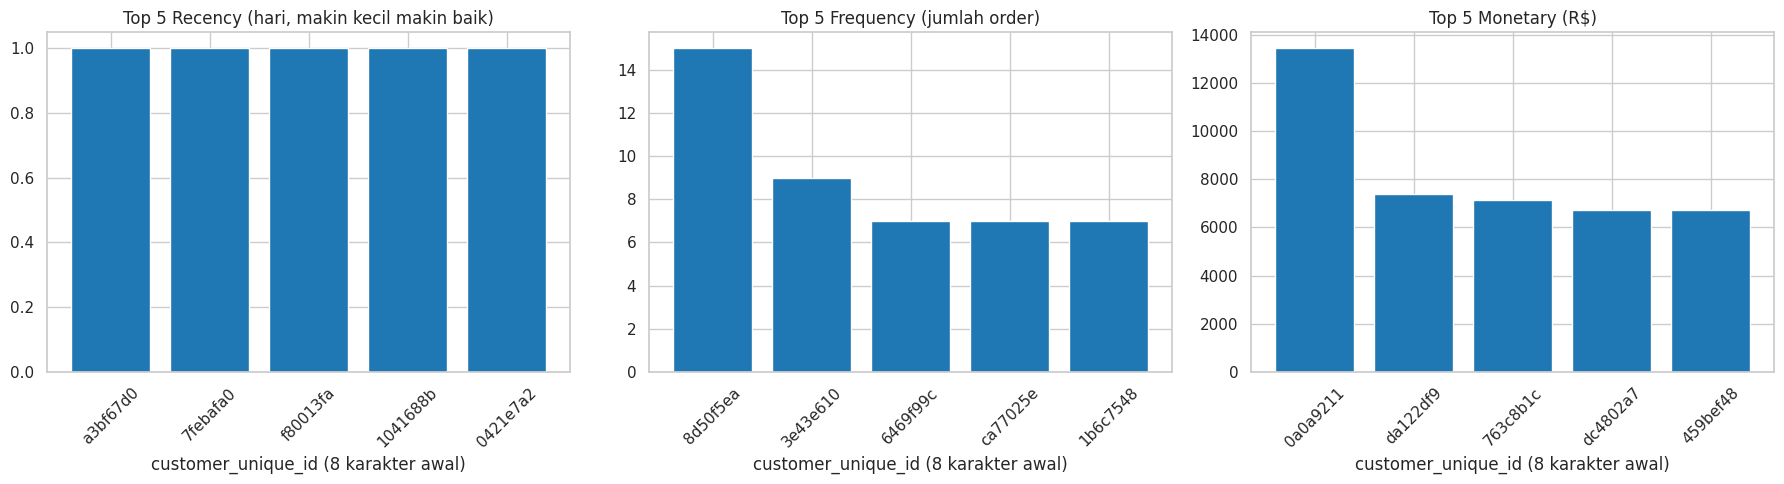

In [64]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
rfm["short_id"] = rfm["customer_unique_id"].str[:8]

by_r = rfm.sort_values("recency", ascending=True).head(5)
ax[0].bar(by_r["short_id"], by_r["recency"], color="#1f77b4")
ax[0].set_title("Top 5 Recency (hari, makin kecil makin baik)")

by_f = rfm.sort_values("frequency", ascending=False).head(5)
ax[1].bar(by_f["short_id"], by_f["frequency"], color="#1f77b4")
ax[1].set_title("Top 5 Frequency (jumlah order)")

by_m = rfm.sort_values("monetary", ascending=False).head(5)
ax[2].bar(by_m["short_id"], by_m["monetary"], color="#1f77b4")
ax[2].set_title("Top 5 Monetary (R$)")

for a in ax:
    a.set_xlabel("customer_unique_id (8 karakter awal)")
    a.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

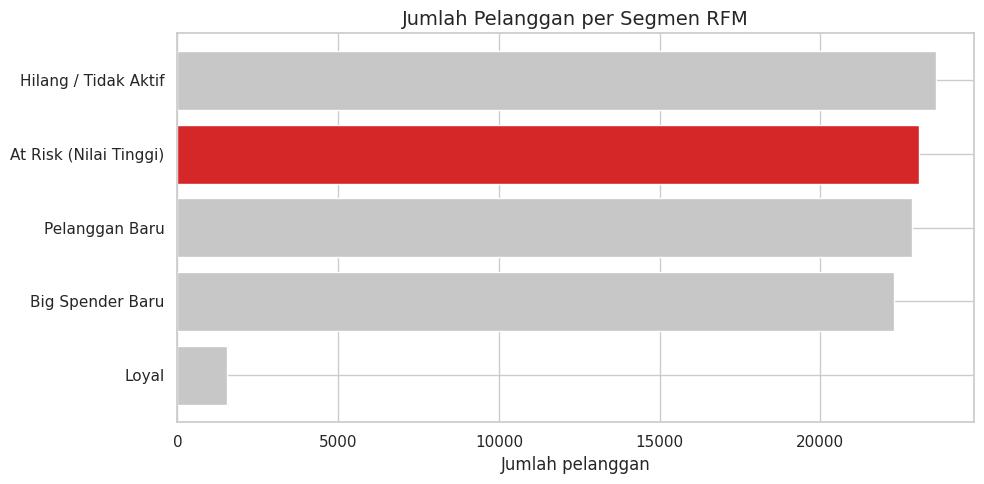

In [65]:
seg_count = rfm["segment"].value_counts()
plt.figure(figsize=(10, 5))
warna = ["#d62728" if s == "At Risk (Nilai Tinggi)" else "#c7c7c7" for s in seg_count.index]
plt.barh(seg_count.index[::-1], seg_count.values[::-1], color=warna[::-1])
plt.title("Jumlah Pelanggan per Segmen RFM", fontsize=14)
plt.xlabel("Jumlah pelanggan")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
Insight dari RFM analysis yg telah dilakukan:
1. Hampir semua pelanggan hanya membeli sekali.
2. Segmen pelanggan loyal sangat kecil, sementara segmen yang perlu diselamatkan besar.
3. Nilai belanja sangat timpang. Rata-rata monetary sekitar R$142, sedangkan mediannya hanya sekitar 90, dan pelanggan teratas mencapai 13.440. Sebagian kecil pelanggan bernilai sangat tinggi menarik rata-rata ke atas.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1, Revenue per kategori (2017) dan tren bulanan:**
1. Kategori teratas didominasi bed_bath_table. Kategori ini memimpin revenue 2017 sebesar sekitar R$490 ribu dan juga memiliki jumlah pesanan terbanyak di antara lima kategori teratas (4.423 pesanan).
2. Revenue bulanan tumbuh pesat sepanjang 2017 dan mencapai puncak di November 2017.
3. Pertumbuhan melambat dan cenderung stabil pada 2018.
- **Conclusion pertanyaan 2, Keterlambatan pengiriman per state:**
1. State dengan persentase keterlambatan tertinggi adalah AL, MA, dan PI.
2. Pesanan yang terlambat mendapat skor review jauh lebih rendah. R
3. Keterlambatan berhubungan erat dengan kepuasan pelanggan di tingkat state.


**Rekomendasi Action Item:**
- Fokuskan stok dan promosi pada kategori unggulan (bed_bath_table, watches_gifts, health_beauty, sports_leisure), dan siapkan kampanye lebih awal menjelang akhir tahun karena revenue memuncak di November 2017.
- Fokuskan stok dan promosi pada kategori unggulan (bed_bath_table, watches_gifts, health_beauty, sports_leisure), dan siapkan kampanye lebih awal menjelang akhir tahun karena revenue memuncak di November 2017.
- Perbaiki logistik di AL, MA, dan PI. Evaluasi mitra pengiriman di wilayah tersebut dan sesuaikan estimasi tiba agar lebih realistis, karena keterlambatan berkaitan erat dengan review rendah.
- Jalankan kampanye reaktivasi untuk segmen At Risk (Nilai Tinggi) dan buat program loyalitas untuk mendorong pembelian ulang, karena 97% pelanggan hanya membeli sekali.

### Menyimpan Main Data


In [66]:
main_export = main[["order_id", "customer_unique_id", "customer_state",
                    "order_purchase_timestamp", "product_category_name_english",
                    "revenue", "review_score", "is_late", "delivery_days"]]
main_export.to_csv("main_data.csv", index=False)

rfm[["customer_unique_id", "recency", "frequency", "monetary",
     "r_score", "f_score", "m_score", "segment"]].to_csv("rfm_data.csv", index=False)

from google.colab import files
files.download("main_data.csv")
files.download("rfm_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>